## Import Libraries

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


## Load Dataset

In [57]:
df = pd.read_csv("../data/ecommerce_sales.csv")

## Basic Inspection

In [58]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Number of rows: 9800
Number of columns: 18

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


## Dataset Information

In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [60]:
df.describe()

,Row ID,Postal Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


In [61]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


## Missing Values

In [62]:
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": df.isnull().mean() * 100
})

missing_values[missing_values["Missing Values"] > 0]

,Missing Values,Percentage
Postal Code,11,0.112245


## Handle Missing Postal Codes

In [63]:
df["Postal Code"] = df["Postal Code"].fillna(0)

In [64]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
dtype: int64

## Check Duplicate Records

In [65]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


## Convert Dates

In [66]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d/%m/%Y",
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d/%m/%Y",
    errors="coerce"
)

In [67]:
df[["Order Date", "Ship Date"]].head()

,Order Date,Ship Date
0,2017-11-08,2017-11-11
1,2017-11-08,2017-11-11
2,2017-06-12,2017-06-16
3,2016-10-11,2016-10-18
4,2016-10-11,2016-10-18


## Create Useful Date Columns

In [68]:
df["Year"] = df["Order Date"].dt.year

df["Month"] = df["Order Date"].dt.month

df["Month_Name"] = df["Order Date"].dt.month_name()

df["Year_Month"] = df["Order Date"].dt.to_period("M").astype(str)

df["Quarter"] = df["Order Date"].dt.quarter

In [69]:
df[
    ["Order Date", "Year", "Month", "Month_Name", "Year_Month", "Quarter"]
].head()

,Order Date,Year,Month,Month_Name,Year_Month,Quarter
0,2017-11-08,2017,11,November,2017-11,4
1,2017-11-08,2017,11,November,2017-11,4
2,2017-06-12,2017,6,June,2017-06,2
3,2016-10-11,2016,10,October,2016-10,4
4,2016-10-11,2016,10,October,2016-10,4


## Create Shipping Duration

In [70]:
df["Shipping_Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

In [71]:
df[
    ["Order Date", "Ship Date", "Shipping_Days"]
].head()

,Order Date,Ship Date,Shipping_Days
0,2017-11-08,2017-11-11,3
1,2017-11-08,2017-11-11,3
2,2017-06-12,2017-06-16,4
3,2016-10-11,2016-10-18,7
4,2016-10-11,2016-10-18,7


## Check Sales

In [72]:
print("Minimum Sales:", df["Sales"].min())
print("Maximum Sales:", df["Sales"].max())
print("Average Sales:", df["Sales"].mean())
print("Total Sales:", df["Sales"].sum())

Minimum Sales: 0.444
Maximum Sales: 22638.48
Average Sales: 230.7690594591837
Total Sales: 2261536.7827000003


## Overall Business Summary

In [73]:
total_sales = df["Sales"].sum()

total_orders = df["Order ID"].nunique()

total_customers = df["Customer ID"].nunique()

total_products = df["Product ID"].nunique()

average_order_value = total_sales / total_orders

average_shipping_days = df["Shipping_Days"].mean()

print("Total Sales:", total_sales)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Average Order Value:", average_order_value)
print("Average Shipping Days:", average_shipping_days)

Total Sales: 2261536.7827000003
Total Orders: 4922
Total Customers: 793
Total Products: 1861
Average Order Value: 459.4751691791955
Average Shipping Days: 3.9611224489795918


## # Monthly Sales Trend


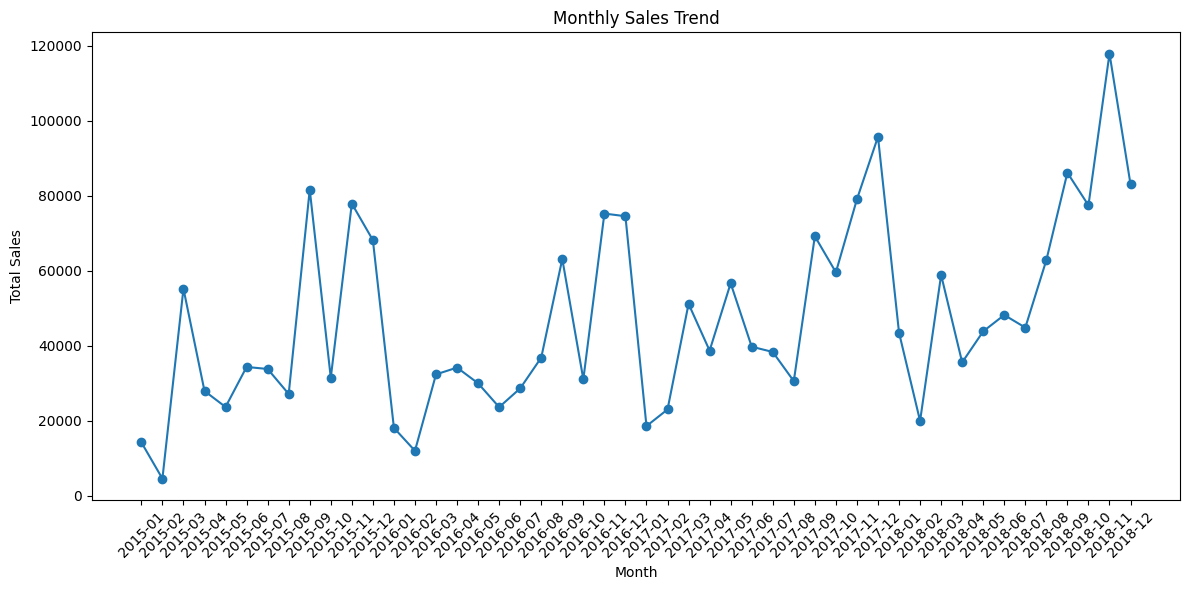

In [74]:
monthly_sales = (
    df.groupby("Year_Month")["Sales"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Year_Month"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../visualizations/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Sales by Category

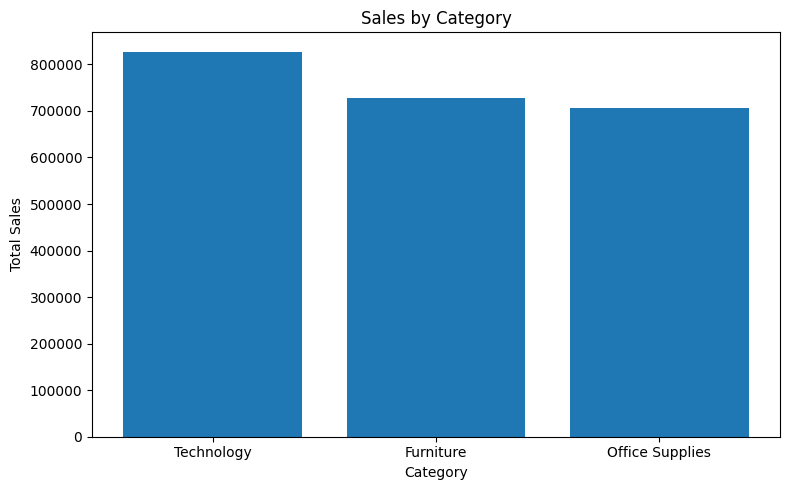

In [75]:
category_sales = (
    df.groupby("Category")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

plt.bar(
    category_sales.index,
    category_sales.values
)

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.tight_layout()

plt.savefig(
    "../visualizations/sales_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Sales by Region

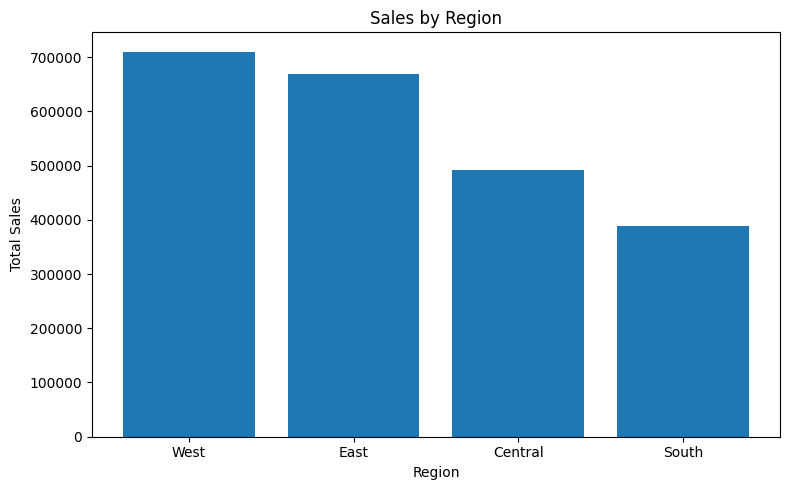

In [76]:
region_sales = (
    df.groupby("Region")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

plt.bar(
    region_sales.index,
    region_sales.values
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.tight_layout()

plt.savefig(
    "../visualizations/sales_by_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Sales by Customer Segment

In [77]:
segment_sales = (
    df.groupby("Segment")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

segment_sales

Segment
Consumer       1.148061e+06
Corporate      6.884941e+05
Home Office    4.249822e+05
Name: Sales, dtype: float64

## Sales by Ship Mode

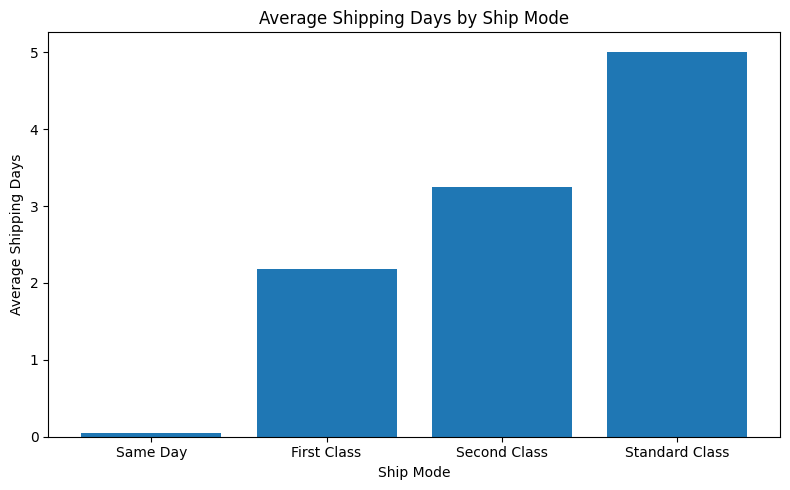

In [78]:
shipping_chart = (
    df.groupby("Ship Mode")["Shipping_Days"]
      .mean()
      .sort_values()
)

plt.figure(figsize=(8, 5))

plt.bar(
    shipping_chart.index,
    shipping_chart.values
)

plt.title("Average Shipping Days by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Average Shipping Days")

plt.tight_layout()

plt.savefig(
    "../visualizations/average_shipping_days.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Top 10 Products

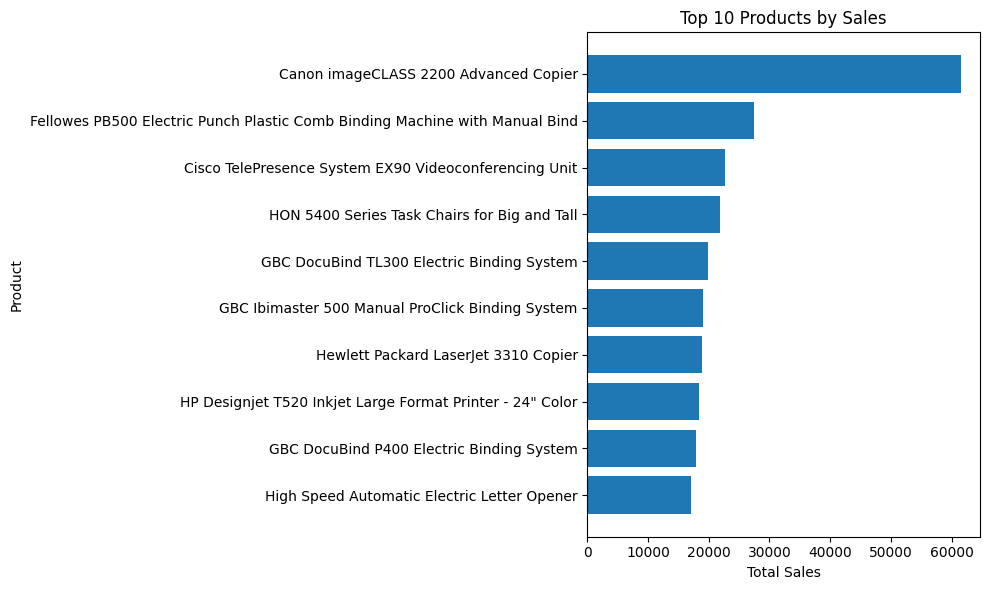

In [79]:
top_products = (
    df.groupby("Product Name")["Sales"]
      .sum()
      .sort_values(ascending=True)
      .tail(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_products.index,
    top_products.values
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    "../visualizations/top_10_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Sales by Sub-Category

In [80]:
subcategory_sales = (
    df.groupby("Sub-Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)
subcategory_sales

Sub-Category
Phones         327782.4480
Chairs         322822.7310
Storage        219343.3920
Tables         202810.6280
Binders        200028.7850
Machines       189238.6310
Accessories    164186.7000
Copiers        146248.0940
Bookcases      113813.1987
Appliances     104618.4030
Furnishings     89212.0180
Paper           76828.3040
Supplies        46420.3080
Art             26705.4100
Envelopes       16128.0460
Labels          12347.7260
Fasteners        3001.9600
Name: Sales, dtype: float64

## Correlation Analysis

In [81]:
numeric_columns = [
    "Sales",
    "Shipping_Days"
]

correlation = df[numeric_columns].corr()

correlation

,Sales,Shipping_Days
Sales,1.000000,-0.005712
Shipping_Days,-0.005712,1.000000


## Outlier Analysis

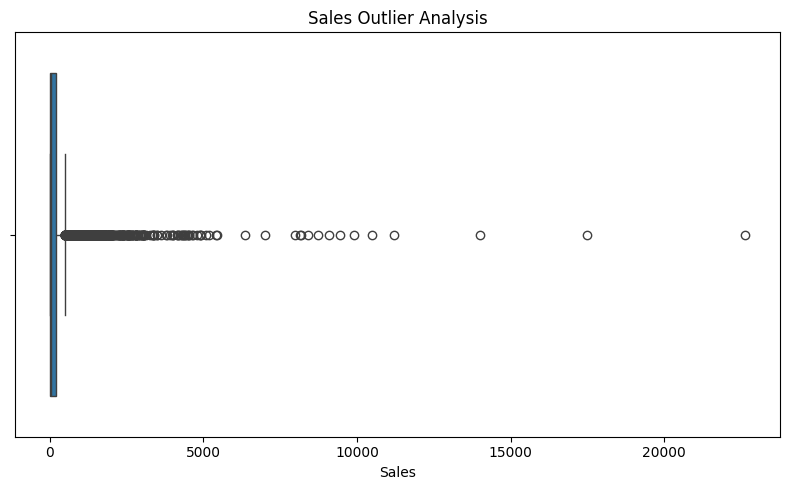

In [82]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Sales"])

plt.title("Sales Outlier Analysis")
plt.xlabel("Sales")

plt.tight_layout()
plt.show()

## Save the Cleaned Dataset

In [83]:
df.to_csv(
    "../data/ecommerce_sales_cleaned.csv",
    index=False
)

## Check the Clean Dataset

In [84]:
cleaned_df = pd.read_csv(
    "../data/ecommerce_sales_cleaned.csv"
)

print(cleaned_df.shape)
print(cleaned_df.isnull().sum().sum())

(9800, 24)
0
